# Evaluasi Kebijakan Kemensos RI melalui Aspect-Based Sentiment Analysis (ABSA) pada Media Sosial

Kementerian Sosial (Kemensos) memegang tanggung jawab atas jaring pengaman sosial nasional. Kebijakan yang dikeluarkan—seperti pengelolaan Data Terpadu Kesejahteraan Sosial (DTKS) dan penyaluran Bantuan Sosial (Bansos)—memiliki dampak langsung terhadap jutaan penduduk kelas bawah. Kesalahan kecil dalam kebijakan atau data dapat menyebabkan gejolak sosial yang signifikan.

Seringkali terdapat jarak antara niat kebijakan di tingkat pusat dengan implementasi di lapangan. Misalnya:

- Akurasi Data: Perubahan sistem dari DTKS ke DTSEN memunculkan isu penetapan "Desil" yang dianggap tidak transparan oleh warga yang merasa tidak mampu tetapi masuk kategori mampu.

- Penerimaan Publik: Kebijakan seperti penghentian bansos bagi pelaku judi online atau aturan izin donasi seringkali memicu perdebatan moral dan birokrasi yang ramai dibicarakan di media sosial.

TikTok dan YouTube telah menjadi saluran utama bagi warga untuk melakukan complaint secara langsung. Dibandingkan lewat jalur resmi, masyarakat lebih cenderung mengunggah keluh kesah mereka di kolom komentar. Data ini bersifat jujur, masif, dan real-time, namun tantangannya adalah datanya sangat tidak terstruktur (kotor).

Pertanyaan Analisis:
1. Kebijakan mana yang paling banyak dibicarakan?
2. Bagaimana distribusi sentimen masyarakat terhadap aspek-aspek spesifik dalam kebijakan tersebut?
3. Apakah terdapat perbedaan pola opini antara pengguna TikTok dan YouTube?

https://www.kaggle.com/datasets/muhammadhabibna/kemensos-sentiment-and-absa-dataset-indonesia

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## First Move

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter

import kagglehub
import re
import os

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/assets/kemensos_kotor.csv")

In [ ]:
df.head()

,Text,Tanggal,Topik,Sumber
0,"data PKH yg sllu utama,datanya tdk prnh dperba...",1.76E+09,DTKS diganti DTSEN,Tiktok
1,saya cek desil saya 2 tapi GK pernah dpt bansos,1.76E+09,DTKS diganti DTSEN,Tiktok
2,betul pak...masa sy desil 8 😁 gak punya ap ap ...,1.76E+09,DTKS diganti DTSEN,Tiktok
3,pantesan saya ga pernah dpt bansos ga tau ny s...,1.76E+09,DTKS diganti DTSEN,Tiktok
4,tdk pernah ada yg survey dan tiba2 ada d desil...,1.76E+09,DTKS diganti DTSEN,Tiktok


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28144 entries, 0 to 28143
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Text     28112 non-null  object
 1   Tanggal  28144 non-null  object
 2   Topik    28144 non-null  object
 3   Sumber   28144 non-null  object
dtypes: object(4)
memory usage: 879.6+ KB


Note :
- Terdapat missing values di kolom 'Text'
- Type data kolom 'Tanggal' masih berupa object

# Data Cleaning

## Missing Values

In [ ]:
# Missing Values
df.isnull().sum()

,0
Text,32
Tanggal,0
Topik,0
Sumber,0


In [ ]:
df = df.dropna(subset=['Text'])

## Data Duplicate

In [ ]:
df.duplicated().sum()

np.int64(1448)

In [ ]:
df = df.drop_duplicates()

## Type Data 'Tanggal'

In [ ]:
# Pisahkan numeric dan non-numeric

mask_numeric = pd.to_numeric(df["Tanggal"], errors="coerce").notna()
df.loc[mask_numeric, "Tanggal"] = pd.to_datetime(
  df.loc[mask_numeric, "Tanggal"].astype(float),
  unit="s",
  utc=True
)


df.loc[~mask_numeric, "Tanggal"] = pd.to_datetime(
  df.loc[~mask_numeric, "Tanggal"],
  utc=True
)

df["Tanggal"] = pd.to_datetime(df["Tanggal"]).dt.tz_convert("Asia/Jakarta").dt.tz_localize(None)

In [ ]:
df.head()

,Text,Tanggal,Topik,Sumber
0,"data PKH yg sllu utama,datanya tdk prnh dperba...",2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok
1,saya cek desil saya 2 tapi GK pernah dpt bansos,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok
2,betul pak...masa sy desil 8 😁 gak punya ap ap ...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok
3,pantesan saya ga pernah dpt bansos ga tau ny s...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok
4,tdk pernah ada yg survey dan tiba2 ada d desil...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok


In [ ]:
df.describe()

,Tanggal
count,26664
mean,2025-10-23 14:38:56.724759808
min,2025-01-15 19:51:24
25%,2025-09-01 11:32:34.500000
50%,2025-10-09 15:53:20
75%,2026-01-12 12:55:23.249999872
max,2026-02-02 09:40:00


In [ ]:
df.describe(include=['object'])

,Text,Topik,Sumber
count,26664,26664,26664
unique,26229,7,2
top,😂,Kemensos Izin donasi,Tiktok
freq,20,9295,16304


# Exploratory Data Analysis

/tmp/ipython-input-1601358211.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Topik', order=df['Topik'].value_counts().index, palette='viridis')


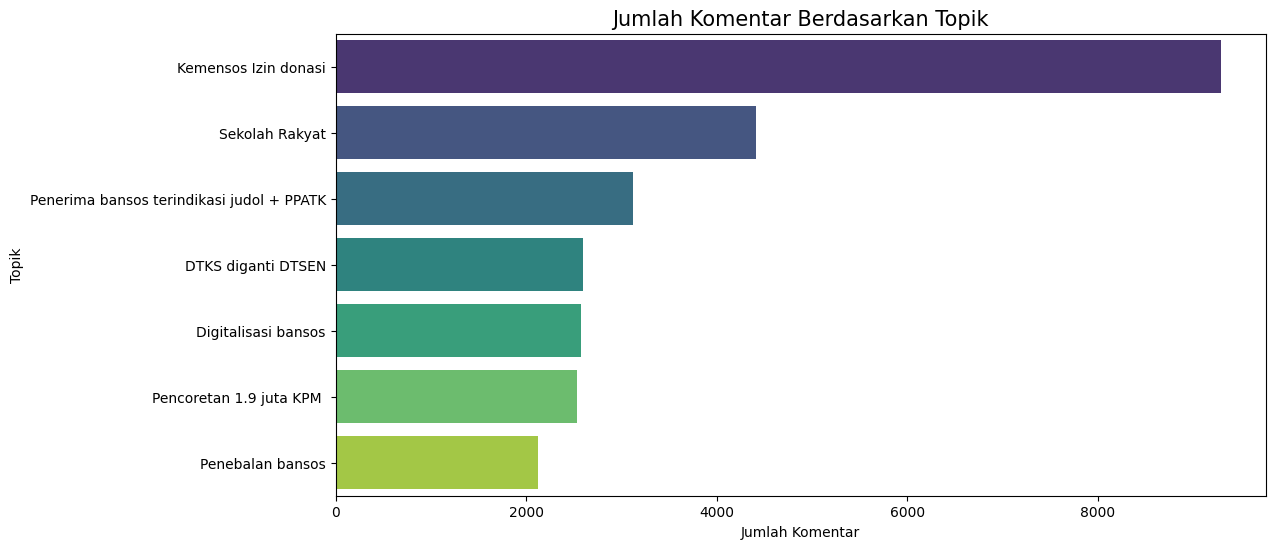

In [ ]:
# Jumlah komentar berdasarkan topik

plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='Topik', order=df['Topik'].value_counts().index, palette='viridis')
plt.title('Jumlah Komentar Berdasarkan Topik', fontsize=15)
plt.xlabel('Jumlah Komentar')
plt.ylabel('Topik')
plt.show()

Berdasarkan grafik distribusi di atas, kita dapat melihat urgensi dan tingkat perhatian masyarakat terhadap berbagai kebijakan Kemensos RI, di mana topik mengenai **perizinan donasi** mendominasi pembicaraan dengan volume mencapai **diatas 8k komentar**. Hal ini menunjukkan adanya *public concern* yang sangat tinggi serta reaksi kritis dari masyarakat terkait kebijakan regulasi penggalangan dana tersebut dibandingkan isu kebijakan lainnya.

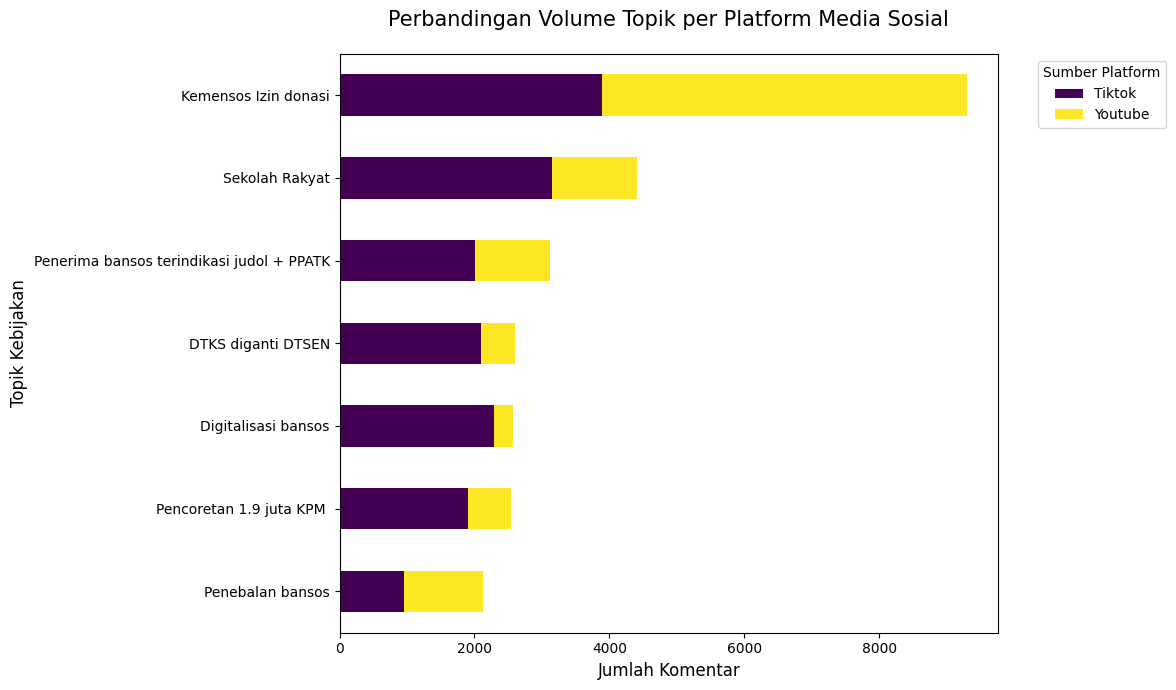

In [ ]:
# Menambahkan variable sumber per topik
ct = pd.crosstab(df['Topik'], df['Sumber'])
ct['Total'] = ct.sum(axis=1)
ct = ct.sort_values('Total', ascending=True).drop(columns=['Total'])
ax = ct.plot(kind='barh', stacked=True, figsize=(12, 7), colormap='viridis')

plt.title('Perbandingan Volume Topik per Platform Media Sosial', fontsize=15, pad=20)
plt.xlabel('Jumlah Komentar', fontsize=12)
plt.ylabel('Topik Kebijakan', fontsize=12)
plt.legend(title='Sumber Platform', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

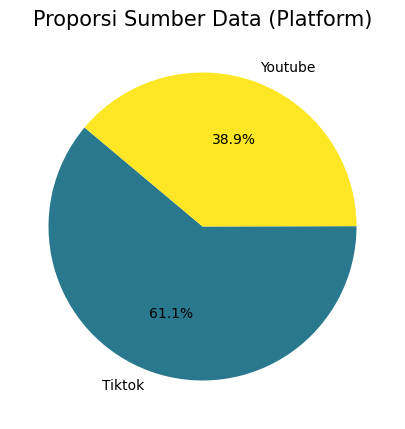

In [ ]:
# Distribusi Sumber
plt.figure(figsize=(8, 5))
source_counts = df['Sumber'].value_counts()

colors = plt.cm.viridis([0.4, 1])

plt.pie(source_counts, labels=source_counts.index, autopct='%1.1f%%', startangle=140, colors=colors)
plt.title('Proporsi Sumber Data (Platform)', fontsize=15)
plt.show()

Hampir 2/3 dari seluruh data berasal dari Sosial Media Tiktok

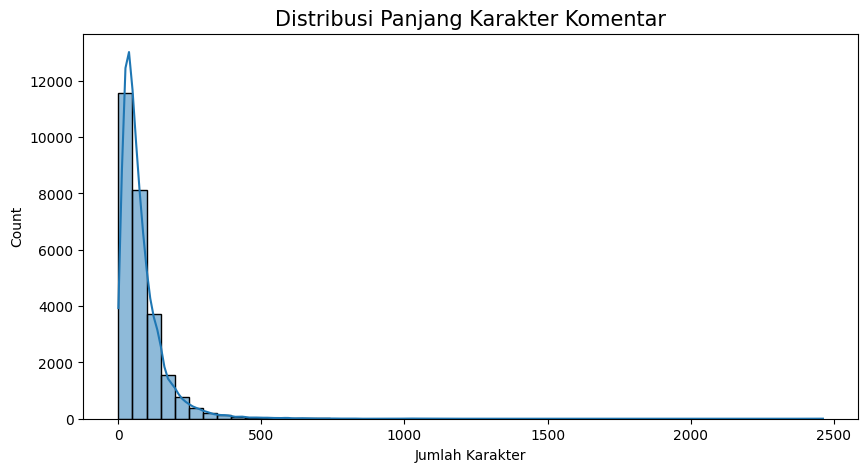

In [ ]:
# TEXT HISTOGRAM

# Menghitung panjang karakter setiap komentar
df['length'] = df['Text'].astype(str).apply(len)

# Distribusi Panjang Komentar
plt.figure(figsize=(10, 5))
sns.histplot(df['length'], bins=50, kde=True)
plt.title('Distribusi Panjang Karakter Komentar', fontsize=15)
plt.xlabel('Jumlah Karakter')
plt.show()

Grafik histogram di atas memberikan gambaran mengenai karakteristik data tekstual sebelum dilakukan pemrosesan lebih lanjut, di mana terlihat distribusi yang miring ke kanan (right-skewed) dengan dominasi komentar singkat di bawah 100 karakter. Hal ini sangat khas untuk platform media sosial seperti TikTok yang cenderung padat dan langsung, meskipun tetap ditemukan keberadaan outlier berupa komentar sangat panjang hingga lebih dari 2.400 karakter yang biasanya berasal dari YouTube. Adanya variasi panjang karakter ini mencerminkan keberagaman narasi, mulai dari opini singkat hingga keluhan detail atau pengalaman pribadi yang nantinya akan memengaruhi strategi ekstraksi aspek dalam analisis sentimen.

Kita akan melihat outliers dari data tersebut

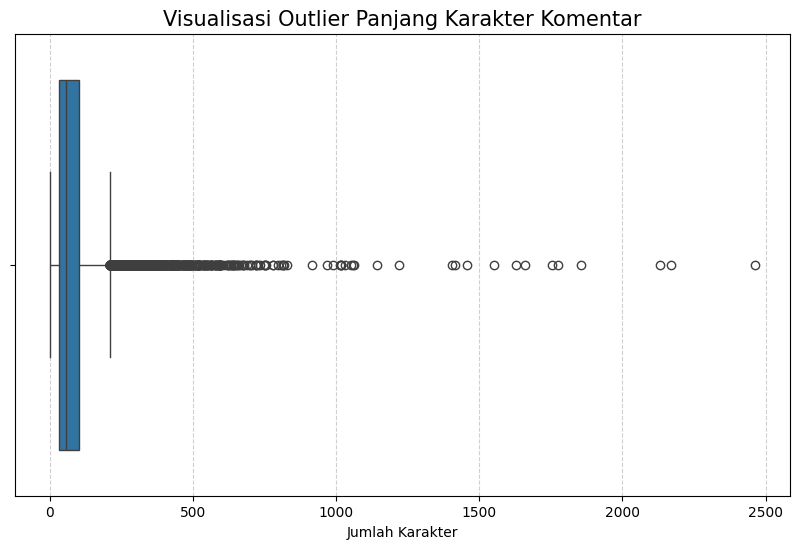

In [ ]:
# BOXPLOT UNTUK OUTLIER

# Visualisasi Outlier dengan Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['length'])

# Menambahkan label dan judul
plt.title('Visualisasi Outlier Panjang Karakter Komentar', fontsize=15)
plt.xlabel('Jumlah Karakter')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# Hitung Q1 dan Q3
Q1_length = df['length'].quantile(0.25)
Q3_length = df['length'].quantile(0.75)

# Hitung IQR
IQR_length = Q3_length - Q1_length

# Tentukan batas atas outlier
ub_length = Q3_length + 1.5 * IQR_length

# Hitung jumlah data di atas outlier
outlier_length_count = df[df['length'] > ub_length].shape[0]
percentage = (outlier_length_count / len(df)) * 100

print("Upper Bound:", ub_length)
print("Jumlah data di atas outlier:", outlier_length_count)
print("Persentase outlier:", round(percentage, 2), "%")



Upper Bound: 209.5
Jumlah data di atas outlier: 1486
Persentase outlier: 5.57 %


In [ ]:
pd.set_option('display.max_colwidth', None)
import textwrap

longest_index = df['length'].idxmax()
longest_text = df.loc[longest_index, 'Text']  # <-- tanpa double bracket

print(textwrap.fill(longest_text, width=160))


Kayak gak tau bagaimana kemilau nya dunia, kayak gak tau bagaimana orang bisa lupa segalanya jika sudah melihat uang, aturan itu diperlukan untuk membuat
transparansi dan memastikan bahwa tidak ada yang bermain di tengah kesedihan orang lain, jika yang mengatakan bahwa diperlukan izin, adalah orang lain yang
notabene bukan pihak yang berwenang, wajar untuk dikritisi, la seng bilang aturan izin diperlukan adalah Mensos yang notabene punya kewenangan dalam perundang-
undangan, wajar saja, banyak orang menari di tengah kesedihan orang, dan kita tidak bisa menutup mata akan hal tersebut, lagipula izinnya tidak dipungut biaya,
dan bisa diakses melalui platform digital, apa yang salah dengan aturan yang bersifat positif, gunakan kedua mata kita dalam menilai seseorang atau pejabat,
jangan sebelah mata, contoh misalnya, anggota DPR pusat yang meminta kepada komdigi atau Kominfo diperiode lalu, untuk menampakkan kinerja nyata pemerintah
terhadap rakyat, apa yang salah dengan permintaan itu, da

Setelah melihat komentar terpanjang, data ini masih terbilang baik. Sehingga kita akan pertahankan

## Timestamp

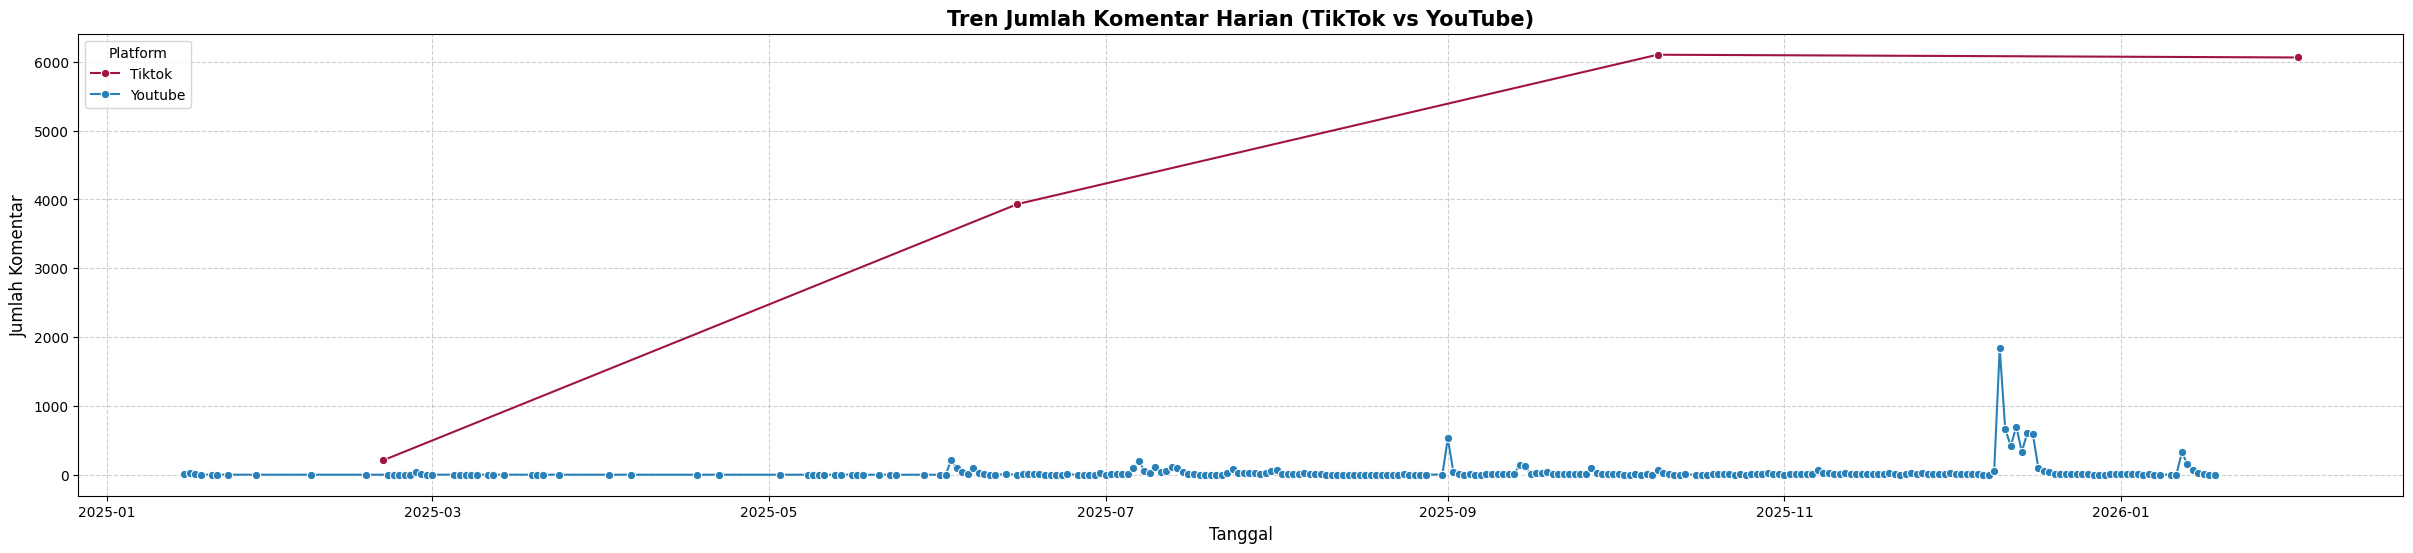

In [ ]:
# ANALISIS TREN WAKTU (TIME SERIES)

df['Date'] = df['Tanggal'].dt.date
daily_trend = df.groupby(['Sumber', 'Date']).size().reset_index(name='Jumlah_Komentar')
colors = {'Tiktok': '#0050EF', 'Youtube': '#D80073'}

# Visualisasi menggunakan Seaborn Line Plot
plt.figure(figsize=(30, 6))
sns.lineplot(
    data=daily_trend,
    x='Date',
    y='Jumlah_Komentar',
    hue='Sumber',
    marker='o',
    palette={'Tiktok': '#A0153E', 'Youtube': '#2980B9'} # Warna identitas platform
)

plt.title('Tren Jumlah Komentar Harian (TikTok vs YouTube)', fontsize=15, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Jumlah Komentar', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Platform')
plt.show()

Terdapat lonjakan yang signifikan di tanggal-tanggal tertentu. Kita juga akan melihat sebaran jamnya

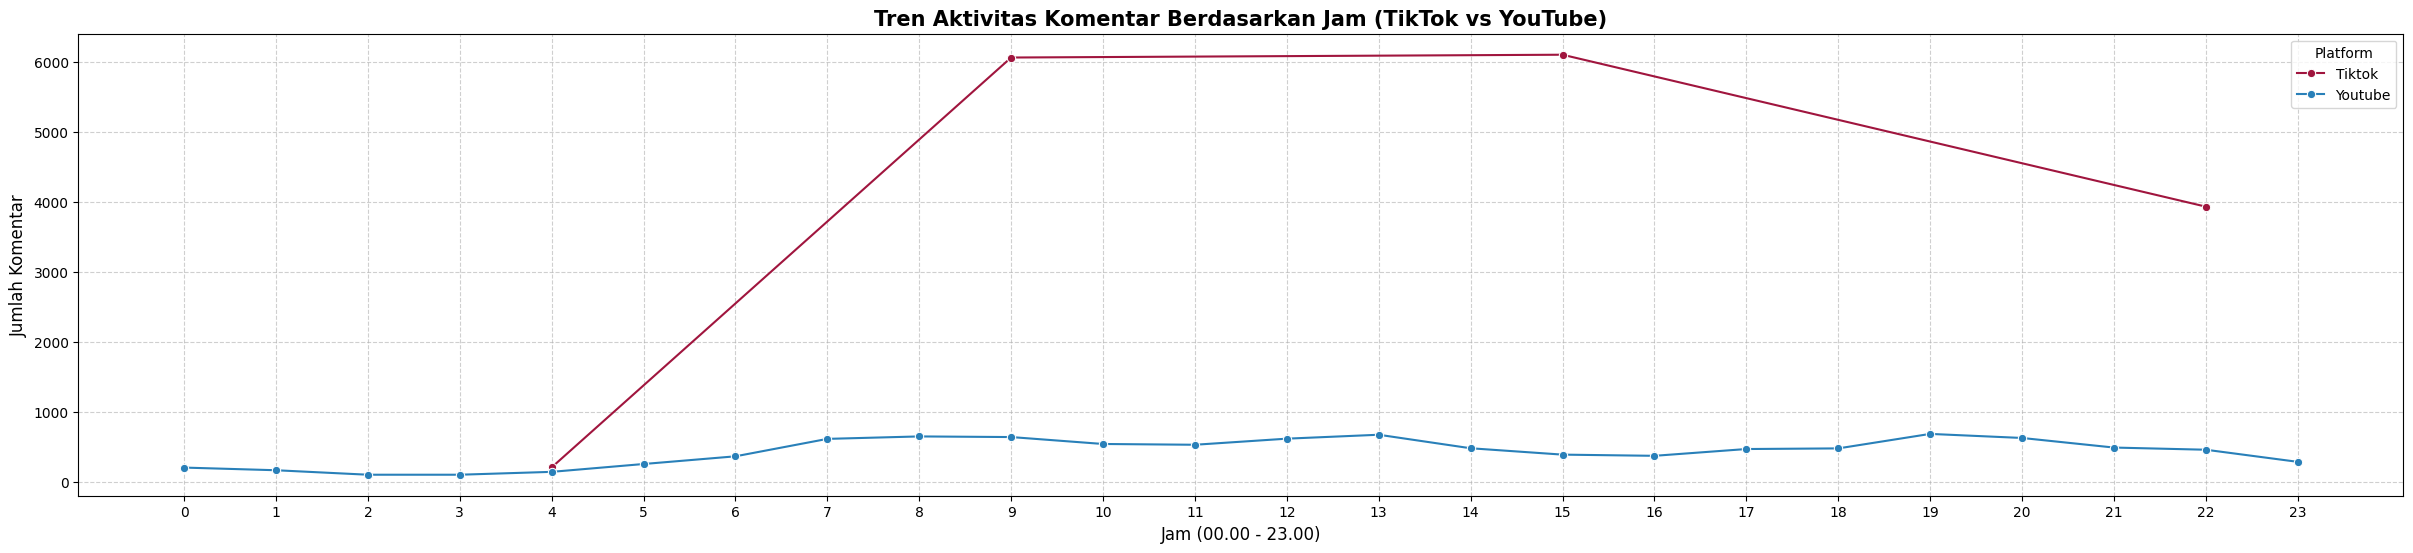

In [ ]:
# Tambahkan kolom baru 'Jam'
df['Jam'] = df['Tanggal'].dt.hour
hourly_dist = df.groupby(['Sumber', 'Jam']).size().reset_index(name='Jumlah_Komentar')

# Visualisasi menggunakan Seaborn Line Plot
plt.figure(figsize=(30, 6))
sns.lineplot(
    data=hourly_dist,
    x='Jam',
    y='Jumlah_Komentar',
    hue='Sumber',
    marker='o',
    palette={'Tiktok': '#A0153E', 'Youtube': '#2980B9'} # Warna identitas platform
)

plt.title('Tren Aktivitas Komentar Berdasarkan Jam (TikTok vs YouTube)', fontsize=15, fontweight='bold')
plt.xlabel('Jam (00.00 - 23.00)', fontsize=12)
plt.ylabel('Jumlah Komentar', fontsize=12)
plt.xticks(range(0, 24)) # Memastikan semua angka jam muncul
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Platform')
plt.show()

Terdapat hal yang aneh untuk sumber tiktok. Kita akan melihat apakah ada keanehan apa lagi dari sumber data tiktok

In [ ]:
# Menghitung jumlah nilai unik pada kolom Tanggal untuk sumber Tiktok
unique_tiktok_dates = df[df['Sumber'] == 'Tiktok']['Tanggal'].nunique()

print(f"Jumlah nilai unik Tanggal di Tiktok: {unique_tiktok_dates}")

Jumlah nilai unik Tanggal di Tiktok: 4


In [ ]:
# Menampilkan 10 nilai tanggal yang paling sering muncul di Tiktok
print("10 Tanggal/Jam paling sering muncul di Tiktok:")
print(df[df['Sumber'] == 'Tiktok']['Tanggal'].value_counts().head(10))

10 Tanggal/Jam paling sering muncul di Tiktok:
Tanggal
2025-10-09 15:53:20    6102
2026-02-02 09:40:00    6062
2025-06-15 22:06:40    3932
2025-02-20 04:20:00     208
Name: count, dtype: int64


Ternyata tiktok hanya menampilkan 4 tanggal dan waktu, hal ini bisa jadi karena classifying atau waktu yang diinput adalah waktu scrapping. Oleh karena itu, kita tidak akan menggunakan variable waktu untuk analisis

## Wordcloud

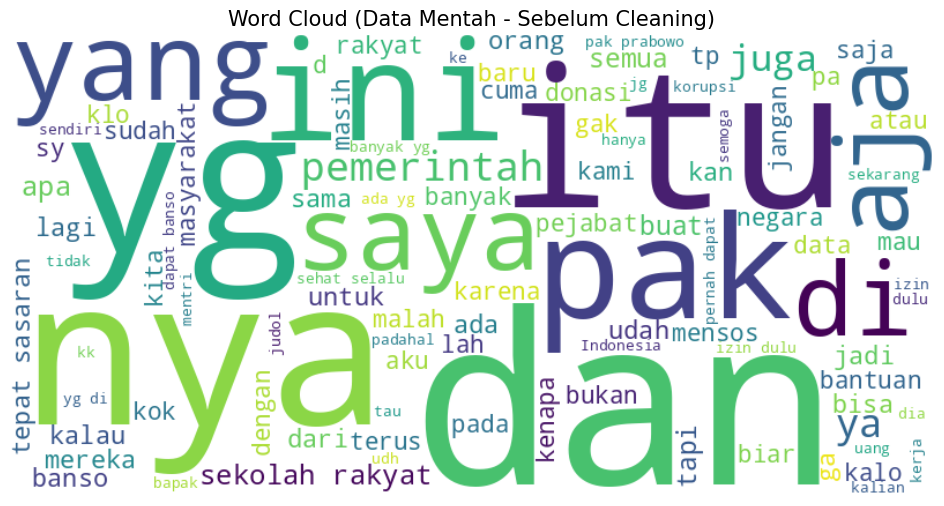

In [ ]:
# Wordcloud sederhana

all_text = ' '.join(df['Text'].astype(str).tolist())

wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud (Data Mentah - Sebelum Cleaning)', fontsize=15)
plt.show()

Seperti yang ada di wordcloud, terdapat banyak sekali noise. Sehingga perlu dibersihkan

### Noise Reduction

In [ ]:
import re

def clean_noise(text):
    text = str(text).lower()                            # mengubah ke lowercase
    text = re.sub(r'https?://\S+|www\.\S+', '', text)   # menghapus url link
    text = re.sub(r'@\w+', '', text)                    # menghapus mention
    text = re.sub(r'#\w+', '', text)                    # menghapus hashtag
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)         # menghapus spesial karakter dan simbol
    text = re.sub(r'\s+', ' ', text).strip()            # menghapus spasi berlebih
    return text

df['Text'] = df['Text'].apply(clean_noise)

In [ ]:
# Scrapping slang words dari kaggle

import kagglehub

path = kagglehub.dataset_download("gabrielmatthew/indonesian-slang-words")
print("Path to dataset files:", path)

100%|██████████| 14.4k/14.4k [00:00<00:00, 18.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/gabrielmatthew/indonesian-slang-words/versions/1


In [ ]:
import os

files = os.listdir(path)
csv_file = [f for f in files if f.endswith('.csv')][0]
full_path = os.path.join(path, csv_file)

slang_df = pd.read_csv(full_path)

In [ ]:
slang_df.head()

,aamiin,amin
0,adek,adik
1,adlh,adalah
2,aer,air
3,aiskrim,es krim
4,aj,saja


In [ ]:
# Memperbaiki nama kolom
slang_df.columns = ['slang', 'formal']
slang_df.head(3)

,slang,formal
0,adek,adik
1,adlh,adalah
2,aer,air


In [ ]:
kamus_slang_auto = dict(zip(slang_df['slang'], slang_df['formal']))

# Menambah istilah kemensos
custom_terms = {
    "kpm": "keluarga penerima manfaat",
    "bansos": "bantuan sosial",
    "pkh": "program keluarga harapan",
    "blt": "bantuan langsung tunai",
    "dtks": "data terpadu kesejahteraan sosial",
    "mensos": "menteri sosial"
}

kamus_slang_auto.update(custom_terms)

In [ ]:
def normalisasi_final(text):
    if not isinstance(text, str): return ""
    # Pecah kalimat, cari di kamus, jika tidak ada pakai kata asli
    words = text.lower().split()
    return " ".join([kamus_slang_auto.get(w, w) for w in words])

# Terapkan ke data Anda
df['Text_Normalized'] = df['Text'].apply(normalisasi_final)

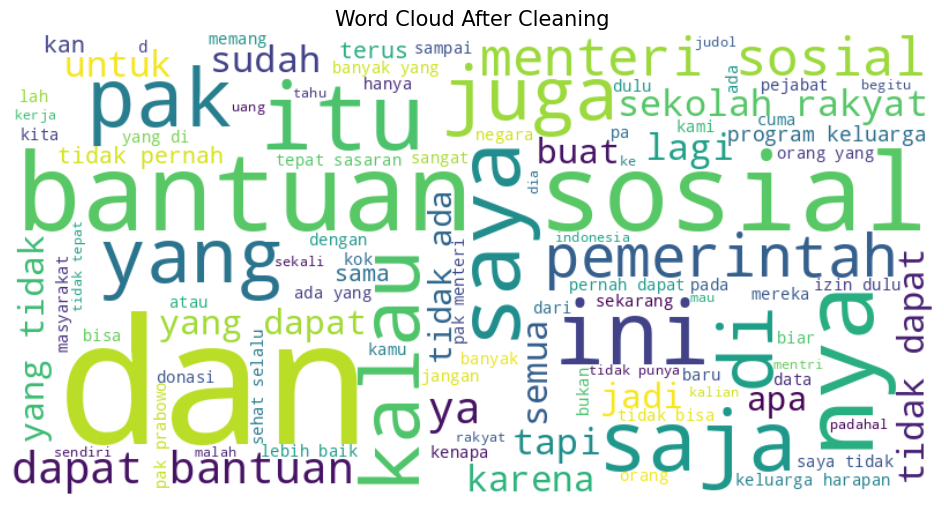

In [ ]:
# Wordcloud sederhana

all_text = ' '.join(df['Text_Normalized'].astype(str).tolist())

wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud After Cleaning', fontsize=15)
plt.show()

In [ ]:
# Menghitung Total Kata (Total Words)
df['total_words'] = df['Text_Normalized'].apply(lambda x: len(str(x).split()))

In [ ]:
# Mengeliminasi kata kosong (seharusnya masih bangian cleaning)
df = df[df['total_words'] >= 1]

In [ ]:
# Menghitung Kata Unik (Unique Words)
df['unique_words'] = df['Text_Normalized'].apply(lambda x: len(set(str(x).split())))

In [ ]:
# Unique Ratio
df['unique_ratio'] = df['unique_words'] / df['total_words']

In [ ]:
df.head()

,Text,Tanggal,Topik,Sumber,length,Jam,Text_Normalized,total_words,unique_words,unique_ratio
0,data pkh yg sllu utama datanya tdk prnh dperbarui org itu aja smpe ke ank cucu,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,81,15,data program keluarga harapan yang selalu utama datanya tidak pernah dperbarui orang itu saja sampai ke anak cucu,18,18,1.000000
1,saya cek desil saya 2 tapi gk pernah dpt bansos,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,47,15,saya cek desil saya 2 tapi tidak pernah dapat bantuan sosial,11,10,0.909091
2,betul pak masa sy desil 8 gak punya ap ap masuk yg elit,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,62,15,betul pak masa saya desil 8 tidak punya ap ap masuk yang elit,13,12,0.923077
3,pantesan saya ga pernah dpt bansos ga tau ny saya desil 5,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,57,15,pantas saya tidak pernah dapat bantuan sosial tidak tahu ny saya desil 5,13,11,0.846154
4,tdk pernah ada yg survey dan tiba2 ada d desil 6 pantes tdk pernah dpt bantuan apa pun,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,86,15,tidak pernah ada yang survey dan tiba2 ada d desil 6 pantes tidak pernah dapat bantuan apa pun,18,15,0.833333


In [ ]:
df

,Text,Tanggal,Topik,Sumber,length,Jam,Text_Normalized,total_words,unique_words,unique_ratio
0,data pkh yg sllu utama datanya tdk prnh dperbarui org itu aja smpe ke ank cucu,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,81,15,data program keluarga harapan yang selalu utama datanya tidak pernah dperbarui orang itu saja sampai ke anak cucu,18,18,1.000000
1,saya cek desil saya 2 tapi gk pernah dpt bansos,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,47,15,saya cek desil saya 2 tapi tidak pernah dapat bantuan sosial,11,10,0.909091
2,betul pak masa sy desil 8 gak punya ap ap masuk yg elit,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,62,15,betul pak masa saya desil 8 tidak punya ap ap masuk yang elit,13,12,0.923077
3,pantesan saya ga pernah dpt bansos ga tau ny saya desil 5,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,57,15,pantas saya tidak pernah dapat bantuan sosial tidak tahu ny saya desil 5,13,11,0.846154
4,tdk pernah ada yg survey dan tiba2 ada d desil 6 pantes tdk pernah dpt bantuan apa pun,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,86,15,tidak pernah ada yang survey dan tiba2 ada d desil 6 pantes tidak pernah dapat bantuan apa pun,18,15,0.833333
...,...,...,...,...,...,...,...,...,...,...
28139,jawir gak tau adab,2025-12-13 14:22:28,Kemensos Izin donasi,Youtube,18,14,jawir tidak tahu adab,4,4,1.000000
28140,ora mutu blas uasuuuu,2025-12-15 07:33:57,Kemensos Izin donasi,Youtube,26,7,ora mutu blas uasuuuu,4,4,1.000000
28141,blunder,2025-12-13 19:48:25,Kemensos Izin donasi,Youtube,7,19,blunder,1,1,1.000000
28142,stop basa basi,2025-12-12 15:47:29,Kemensos Izin donasi,Youtube,14,15,stop basa basi,3,3,1.000000


## Check Point 1 (After EDA)

In [ ]:
df.to_csv('kemensos_02.csv', index=False)
print("File 'kemensos_02.csv' is saved!")

File 'kemensos_02.csv' is saved!


# Sentiment Analysis

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter

import kagglehub
import re
import os

from tqdm import tqdm
from transformers import pipeline

tqdm.pandas()

In [ ]:
df_02 = pd.read_csv('kemensos_02.csv')

In [ ]:
# Load model sentimen bahasa Indonesia
pretrained_name = "w11wo/indonesian-roberta-base-sentiment-classifier"
sentiment_pipe = pipeline("sentiment-analysis", model=pretrained_name)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: w11wo/indonesian-roberta-base-sentiment-classifier
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
def get_sentiment(Text_Normalized):
    try:
        result = sentiment_pipe(Text_Normalized[:512])[0]
        return result['label']
    except:
        return "Neutral"

df_02['sentiment'] = df_02['Text_Normalized'].progress_apply(get_sentiment)

100%|██████████| 26243/26243 [58:46<00:00,  7.44it/s]


In [ ]:
df_02

,Text,Tanggal,Topik,Sumber,length,Jam,Text_Normalized,total_words,unique_words,unique_ratio,sentiment
0,data pkh yg sllu utama datanya tdk prnh dperbarui org itu aja smpe ke ank cucu,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,81,15,data program keluarga harapan yang selalu utama datanya tidak pernah dperbarui orang itu saja sampai ke anak cucu,18,18,1.000000,positive
1,saya cek desil saya 2 tapi gk pernah dpt bansos,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,47,15,saya cek desil saya 2 tapi tidak pernah dapat bantuan sosial,11,10,0.909091,negative
2,betul pak masa sy desil 8 gak punya ap ap masuk yg elit,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,62,15,betul pak masa saya desil 8 tidak punya ap ap masuk yang elit,13,12,0.923077,negative
3,pantesan saya ga pernah dpt bansos ga tau ny saya desil 5,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,57,15,pantas saya tidak pernah dapat bantuan sosial tidak tahu ny saya desil 5,13,11,0.846154,negative
4,tdk pernah ada yg survey dan tiba2 ada d desil 6 pantes tdk pernah dpt bantuan apa pun,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,86,15,tidak pernah ada yang survey dan tiba2 ada d desil 6 pantes tidak pernah dapat bantuan apa pun,18,15,0.833333,negative
...,...,...,...,...,...,...,...,...,...,...,...
26238,jawir gak tau adab,2025-12-13 14:22:28,Kemensos Izin donasi,Youtube,18,14,jawir tidak tahu adab,4,4,1.000000,negative
26239,ora mutu blas uasuuuu,2025-12-15 07:33:57,Kemensos Izin donasi,Youtube,26,7,ora mutu blas uasuuuu,4,4,1.000000,negative
26240,blunder,2025-12-13 19:48:25,Kemensos Izin donasi,Youtube,7,19,blunder,1,1,1.000000,negative
26241,stop basa basi,2025-12-12 15:47:29,Kemensos Izin donasi,Youtube,14,15,stop basa basi,3,3,1.000000,negative


In [ ]:
df_02[df_02['sentiment'] == 'neutral'][['Text_Normalized', 'sentiment']]

,Text_Normalized,sentiment
7,saya ibu rumah tangga single mom tapi terkena desil 7 tidak ada survei,neutral
22,tapi pak buat lansia tua rentan tadi nya kebagian bantuan sekarang tidak pak,neutral
26,pak saya mau tanya siapa sih yang menentukan desil itu pak,neutral
40,aaah nge datanya dari rumah petugaasnya yang knal dn eket dmsukin data aplgi klwra dn sohib karib,neutral
47,dtsen bikin curat marut y pencairan lagi jaman y bu risma jadi menteri sosial tidak seperti ini tuh lancar saja,neutral
...,...,...
26169,pul pul kakean crito sumbangan dari pemerintah spa sudah kamu salurkan,neutral
26172,bp mentri otaknya kadang kadang of kadang kadang on,neutral
26222,menteri sosial konslet,neutral
26226,mensos2 kepiye iki,neutral


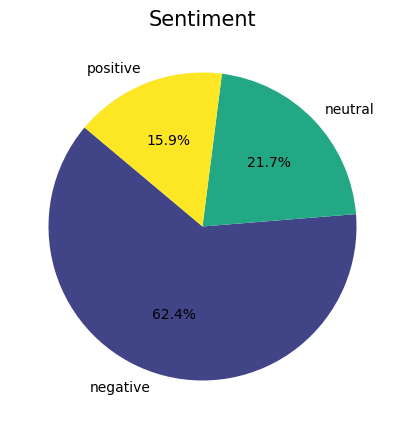

In [ ]:
# Distribusi Sumber
plt.figure(figsize=(8, 5))
source_counts = df_02['sentiment'].value_counts()

colors = plt.cm.viridis([0.2, 0.6, 1.0])

plt.pie(source_counts, labels=source_counts.index, autopct='%1.1f%%', startangle=140, colors=colors)
plt.title('Sentiment', fontsize=15)
plt.show()

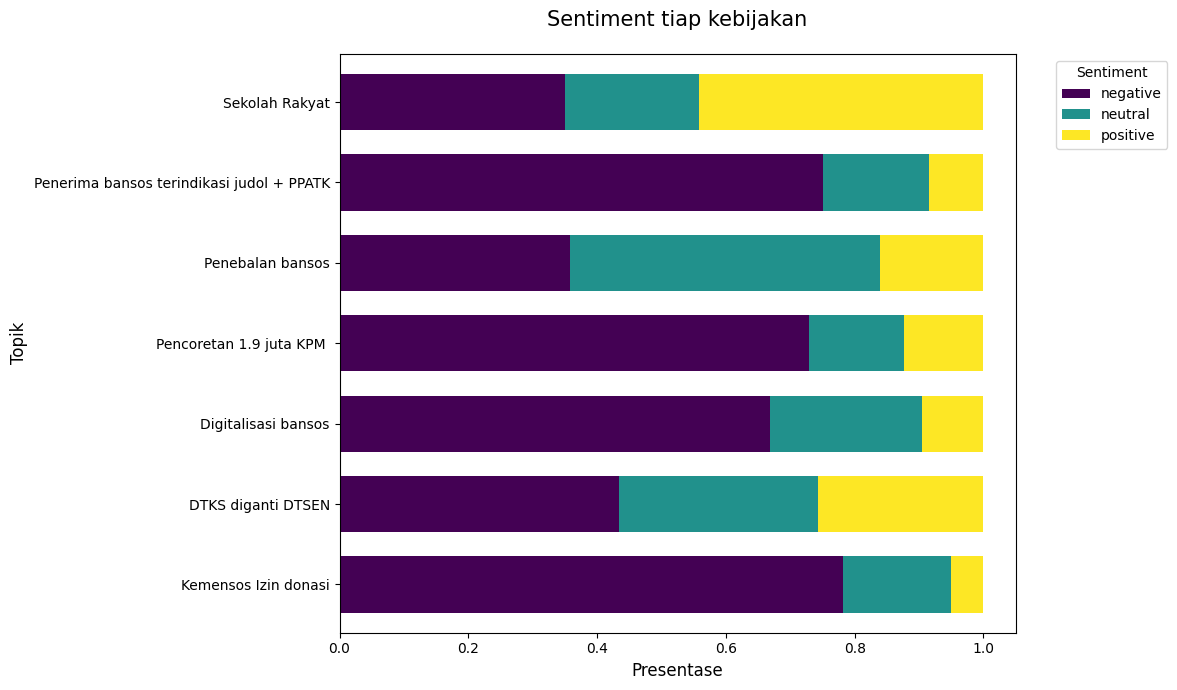

In [ ]:
# Sentiment analysis per topik
ct = pd.crosstab(df_02['Topik'], df_02['sentiment'], normalize='index')
ct['Total'] = ct.sum(axis=1)
ct = ct.sort_values('Total', ascending=True).drop(columns=['Total'])
ax = ct.plot(kind='barh', stacked=True, figsize=(12, 7), colormap='viridis', width=0.7)

plt.title('Sentiment tiap kebijakan', fontsize=15, pad=20)
plt.xlabel('Presentase', fontsize=12)
plt.ylabel('Topik', fontsize=12)
plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## Check Point 3 (After Sentiment Analysis)

In [ ]:
# Tentukan folder tujuan di Google Drive Anda
folder_path = '/content/drive/MyDrive/Colab Notebooks/assets/'
file_name = 'kemensos_03.csv'

full_path = folder_path + file_name
df_02.to_csv(full_path, index=False)

print(f"File berhasil disimpan secara permanen di Drive: {full_path}")

File berhasil disimpan secara permanen di Drive: /content/drive/MyDrive/Colab Notebooks/assets/kemensos_03.csv


# Aspect-Base Sentiment Classification (ABSC)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter

import kagglehub
import re
import os
from itertools import combinations
from collections import Counter

from tqdm import tqdm
from transformers import pipeline

tqdm.pandas()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df_03 = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/assets/kemensos_03.csv")

In [ ]:
df_03.head()

,Text,Tanggal,Topik,Sumber,length,Jam,Text_Normalized,total_words,unique_words,unique_ratio,sentiment
0,data pkh yg sllu utama datanya tdk prnh dperba...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,81,15,data program keluarga harapan yang selalu ut...,18,18,1.000000,positive
1,saya cek desil saya 2 tapi gk pernah dpt bansos,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,47,15,saya cek desil saya 2 tapi tidak pernah dapat ...,11,10,0.909091,negative
2,betul pak masa sy desil 8 gak punya ap ap masu...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,62,15,betul pak masa saya desil 8 tidak punya ap ap...,13,12,0.923077,negative
3,pantesan saya ga pernah dpt bansos ga tau ny s...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,57,15,pantas saya tidak pernah dapat bantuan sosia...,13,11,0.846154,negative
4,tdk pernah ada yg survey dan tiba2 ada d desil...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,86,15,tidak pernah ada yang survey dan tiba2 ada d ...,18,15,0.833333,negative


In [ ]:
sub_aspects = {
    'Akurasi & Sistem': [
        'desil', 'sasaran', 'mampu', 'miskin', 'verifikasi', 'hapus', 'coret', 'data', 'penerima',
        'tidak jelas', 'bingung', 'gimana', 'bagaimana', 'tidak paham', 'daftar dimana', 'caranya',
        'transparansi', 'transparan', 'pendapat', 'dikurangi', 'laporan', 'audit', 'lapor',
        'terdaftar', 'aplikasi', 'apk', 'error', 'eror', 'link', 'sanggahan', 'kosong', 'bnpt', 'palsu', 'hoax',
        'survey', 'lenyap', 'internet', 'online', 'digital', 'media sosial', 'beres', 'saran'
    ],

    'Kinerja & Birokrasi': [
        'cair', 'ambil', 'atm', 'bank', 'pos', 'himbara', 'lama', 'tunggu', 'pindah', 'saldo',
        'ribet', 'berbelit', 'prosedur', 'alur', 'dokumen', 'persyaratan', 'bolak balik', 'repot', 'persulit',
        'tidak becus', 'gagal', 'buruk', 'amburadul', 'memalukan', 'payah', 'kinerja', 'nyusahin',
        'goblok', 'tolol', 'jahat', 'parah', 'bego', 'bodoh', 'lemot', 'kacau', 'blunder', 'otak',
        'hati', 'bobrok', 'pintar', 'panik', 'koplak', 'dongo', 'geblek', 'idiot', 'gila', 'gendeng',
        'eusak', 'sick', 'pecat', 'mantri', 'muak', 'direspon', 'sidak', 'pamong', 'aparat', 'pns',
        'urus', 'pendamping', 'bagian', 'bosan', 'capek', 'jengkel', 'terjun',
        'rumit', 'gubris', 'seleksi', 'pekerjaan', 'lowongan', 'lapangan kerja', 'plonga plongo', 'tambal', 'semrawut', 'kemendikbud'
    ],

    'Keadilan & Dampak Sosial': [
        'tidak adil', 'pilih kasih', 'diskriminasi', 'tidak merata', 'tebang pilih', 'zonk', 'janda', 'lansia',
        'biaya', 'utang', 'penghasilan', 'nafkah', 'ekonomi susah', 'makan', 'kelaparan', 'perut',
        'lapar', 'darurat', 'keburu mati', 'mendesak', 'nyawa', 'bencana', 'rakyat', 'sakit', 'kemanusiaan',
        'nangis', 'sedih', 'kasihan', 'dzolim', 'tega', 'sengsara', 'zolim', 'zoliiim', 'dzalim', 'banjir',
        'longsor', 'tambang', 'pengertian', 'gaji', 'belum merdeka', 'stress', 'cemas', 'menebang hutan', 'urgent',
        'sembako', 'sosial', 'susah', 'kenyataan', 'iri', 'penebalan', 'keluarga', 'harapan', 'tunai', 'pedagang',
        'kebagian', 'mbg', 'pendidikan', 'gratis', 'realita', 'makmur', 'ekonomi', 'hancur', 'warga', 'desa', 'merata', 'mahal', 'rabun'
    ],

    'Integritas & Politik': [
        'tidak percaya', 'bohong', 'settingan', 'pencitraan', 'akal akalan', 'drama', 'sandiwara', 'formalitas',
        'korupsi', 'koruptop', 'koruptor', 'korup', 'potong', 'sunat', 'duit', 'uang', 'tilep',
        'politik', 'kampanye', 'cari suara', 'agenda', 'elektoral', '2029', 'coblos', 'suara',
        'gus ipul', 'saifullah yusuf', 'menteri', 'pejabat', 'muka', 'cari nama', 'pemerintah', 'jokowi',
        'penipu', 'pengkhianat', 'licik', 'lengserkan', 'mencla', 'mencle', 'jarah', 'iblis', 'setan', 'revolusi',
        'kpk', 'buzzer', 'nyelengewan', 'penyelewengan', 'disalahgunakan', 'dipalak', 'mewah', 'mobil', 'kaya', 'omon',
        'judol', 'bandar', 'dpr', 'senioritas', 'patriot', 'doktrin', 'bully', 'pembulian', 'dipaksa', 'rasis', 'npd',
        'suap', 'titipan', 'bonus', 'usulan', 'antek', 'rt', 'rw', 'perangkat'
    ],

    'Regulasi & Hukum': [
        'ngatur', 'mengatur', 'ikut campur', 'hak', 'donatur', 'dilarang ngatur',
        'penjara', 'denda', 'pidana', 'tangkap', 'hukum', 'kriminal', 'pasal', 'polisi', 'pajak', 'ditutup',
        'bubarkan', 'hentikan', 'turunkan',
        'tutup', 'demo', 'blokir', 'brantas', 'berantas'
    ],

    'Solidaritas & Sinisme': [
        'ferry irwandi', 'bang rama', 'lebih berguna', 'gercep', 'relawan', 'rakyat bantu rakyat', 'sumbangan', 'amal',
        'konoha', 'israel lokal', 'kocak', 'lucu', 'dagelan', 'aneh', 'opo to', 'preeettt', 'hehehe', 'mikir',
        'bersaing', 'komedi', 'bermanfaat', 'basa basi', 'bacot'
    ]
}

In [ ]:
# def analyze_absc(text):
#     text = str(text).lower()
#     text = text.replace('ijin', 'izin').replace('mentri', 'menteri')

#     matched_aspects = []
#     matched_keywords = []

#     for aspect, keywords in sub_aspects.items():
#         found = [word for word in keywords if word in text]
#         if found:
#             matched_aspects.append(aspect)
#             matched_keywords.extend(found)

#     if not matched_aspects:
#         return ['Lainnya / Umum'], []

#     return matched_aspects, list(set(matched_keywords))

In [ ]:
def analyze_absc(text):
    text = str(text).lower()
    text = text.replace('ijin', 'izin').replace('mentri', 'menteri')

    # Gunakan list untuk menampung pasangan (tuple) agar unik
    pairs = []

    for aspect, keywords in sub_aspects.items():
        found = [word for word in keywords if word in text]
        for word in found:
            # Setiap ketemu 1 kata, simpan pasangannya dengan aspeknya
            pairs.append((aspect, word))

    if not pairs:
        return ['Lainnya / Umum'], []

    # Hilangkan duplikat jika ada kata yang sama terdeteksi dua kali
    unique_pairs = list(set(pairs))

    # Pecah kembali menjadi dua list yang PANJANGNYA PASTI SAMA
    final_aspects = [p[0] for p in unique_pairs]
    final_keywords = [p[1] for p in unique_pairs]

    return final_aspects, final_keywords

In [ ]:
# Kolom Baru

df_03[['sub_aspect_list', 'keywords_found']] = df_03['Text_Normalized'].apply(
    lambda x: pd.Series(analyze_absc(x))
)

df_03['primary_aspect'] = df_03['sub_aspect_list'].apply(lambda x: x[0])
df_03['aspect_count'] = df_03['sub_aspect_list'].apply(len)
df_03['is_multi_issue'] = df_03['aspect_count'] > 1

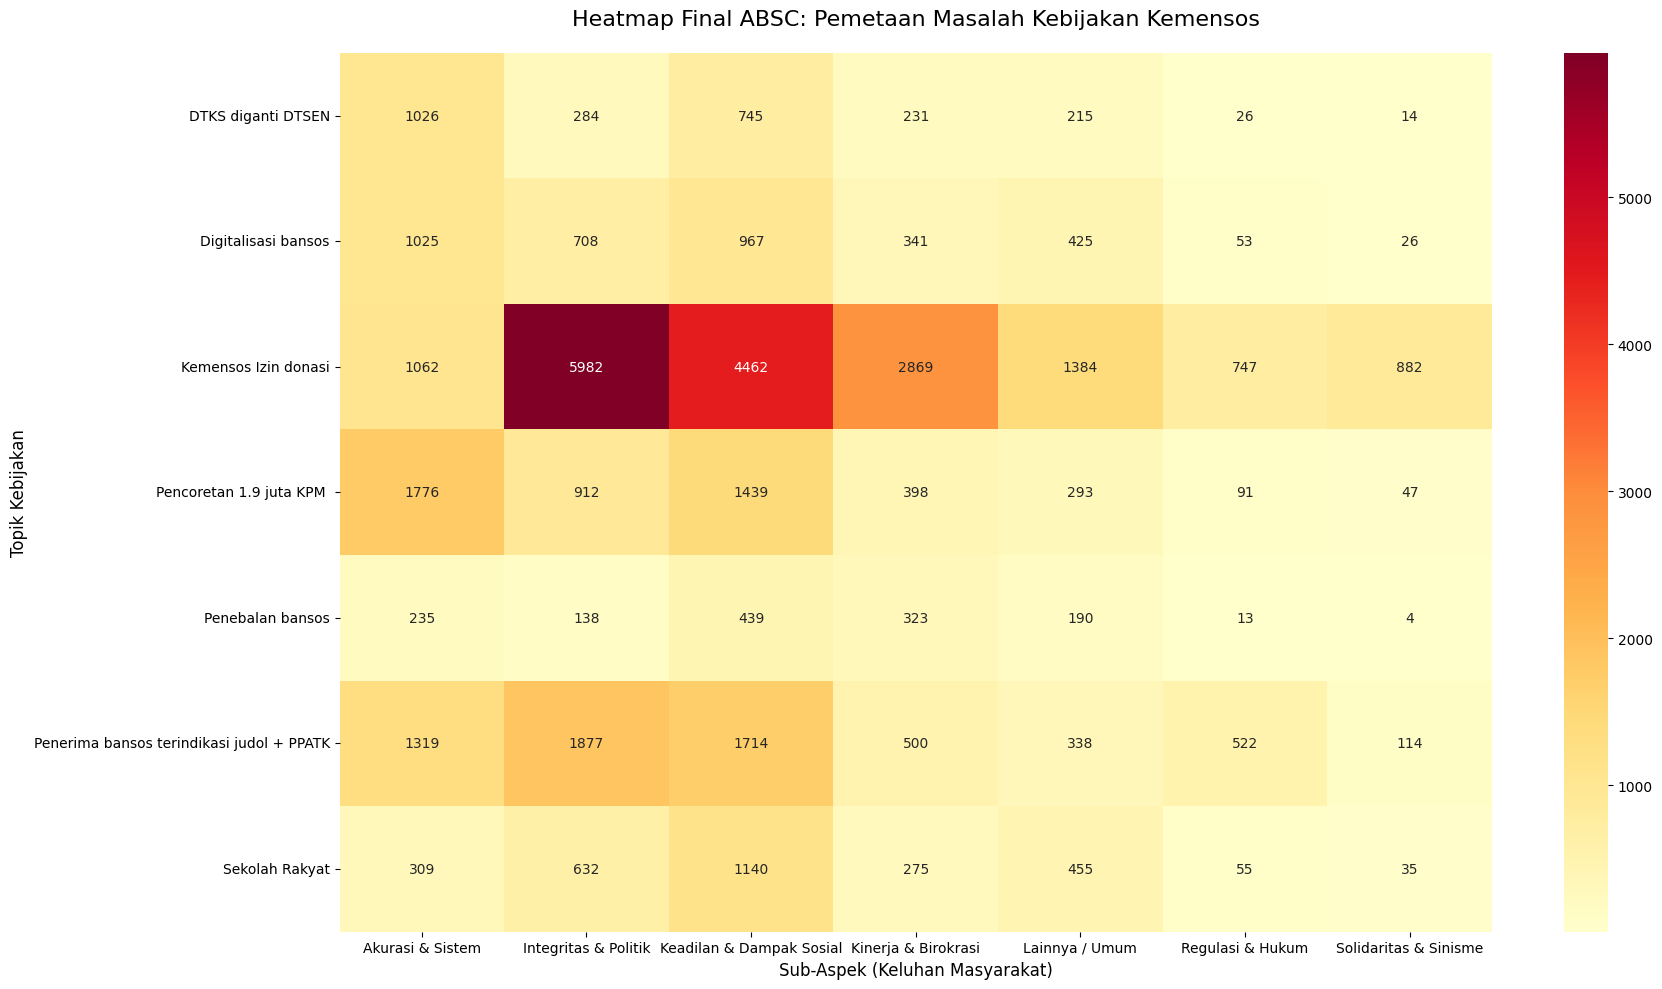

In [ ]:
# TOPIK VS ASPECT

df_exploded = df_03.explode('sub_aspect_list')
df_neg = df_exploded[df_exploded['sentiment'] == 'negative']

heatmap_data = pd.crosstab(df_neg['Topik'], df_neg['sub_aspect_list'])

plt.figure(figsize=(18, 10))
sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Heatmap Final ABSC: Pemetaan Masalah Kebijakan Kemensos', fontsize=16, pad=20)
plt.xlabel('Sub-Aspek (Keluhan Masyarakat)', fontsize=12)
plt.ylabel('Topik Kebijakan', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# PASANGAN MASALAH

pairs_list = []
for aspects in df_03[df_03['sentiment'] == 'negative']['sub_aspect_list']:
    if len(aspects) > 1:
        pairs = list(combinations(sorted(aspects), 2))
        pairs_list.extend(pairs)

pair_counts = Counter(pairs_list)

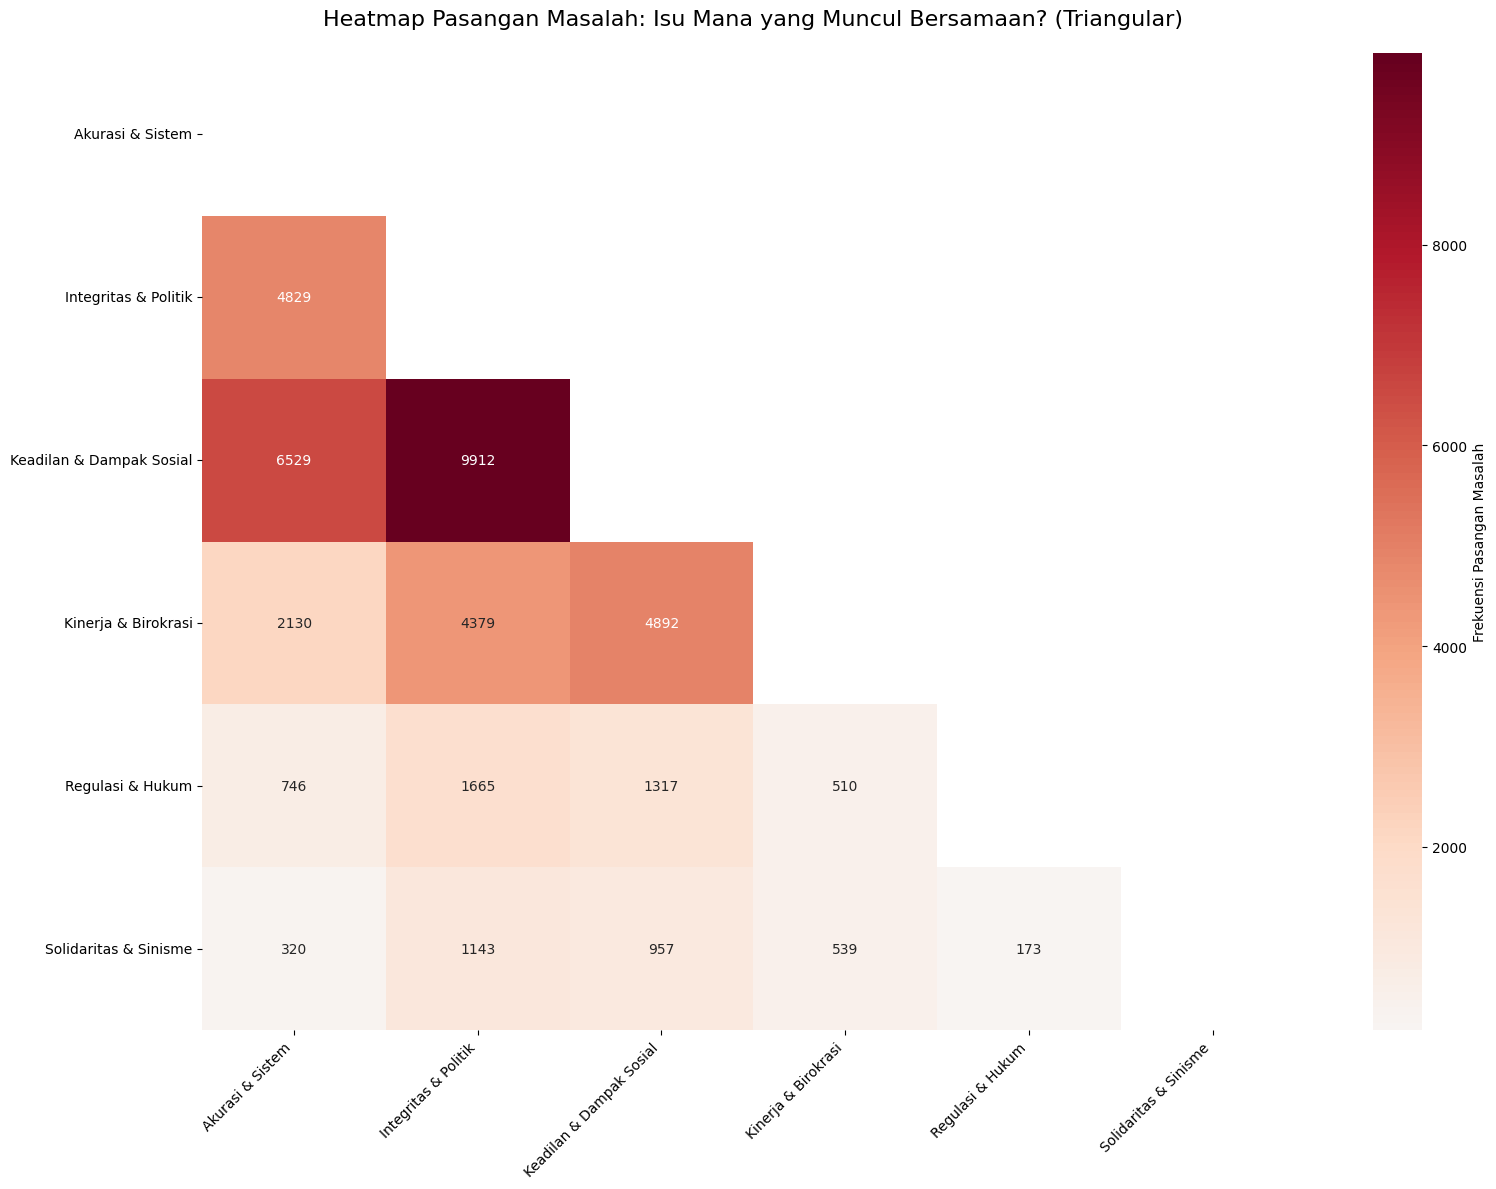

In [ ]:
# MATRIX PREPARATION

all_cats = sorted(sub_aspects.keys())
matrix = pd.DataFrame(0, index=all_cats, columns=all_cats)
for (a, b), count in pair_counts.items():
    matrix.loc[a, b] = count
    matrix.loc[b, a] = count


mask = np.triu(np.ones_like(matrix, dtype=bool))
plt.figure(figsize=(16, 12))

sns.heatmap(matrix,
            mask=mask,
            annot=True,
            fmt='d',
            cmap='RdBu_r',
            center=0,
            cbar_kws={'label': 'Frekuensi Pasangan Masalah'})

plt.title('Heatmap Pasangan Masalah: Isu Mana yang Muncul Bersamaan? (Triangular)', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Save The Final File

In [ ]:
# Cara terbaik: Menambahkan di posisi kolom ke-0 (paling kiri)
df_03.insert(0, 'id', range(1, len(df_03) + 1))

In [ ]:
df_03.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26243 entries, 0 to 26242
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               26243 non-null  int64  
 1   Text             26243 non-null  object 
 2   Tanggal          26243 non-null  object 
 3   Topik            26243 non-null  object 
 4   Sumber           26243 non-null  object 
 5   length           26243 non-null  int64  
 6   Jam              26243 non-null  int64  
 7   Text_Normalized  26243 non-null  object 
 8   total_words      26243 non-null  int64  
 9   unique_words     26243 non-null  int64  
 10  unique_ratio     26243 non-null  float64
 11  sentiment        26243 non-null  object 
 12  sub_aspect_list  26243 non-null  object 
 13  keywords_found   26243 non-null  object 
 14  primary_aspect   26243 non-null  object 
 15  aspect_count     26243 non-null  int64  
 16  is_multi_issue   26243 non-null  bool   
dtypes: bool(1), 

In [ ]:
# Tentukan folder tujuan di Google Drive Anda

folder_path = '/content/drive/MyDrive/Colab Notebooks/assets/'
file_name = 'kemensos_final.csv'

full_path = folder_path + file_name
df_03.to_csv(full_path, index=False)

print(f"File berhasil disimpan secara permanen di Drive: {full_path}")

File berhasil disimpan secara permanen di Drive: /content/drive/MyDrive/Colab Notebooks/assets/kemensos_final.csv


In [ ]:
df_03.to_csv('kemensos_sentiment.csv', index=False)

# Deep Dive Analysis

## Aspect Density Analysis

/tmp/ipython-input-3556205230.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=density_analysis.values, y=density_analysis.index, palette='viridis')


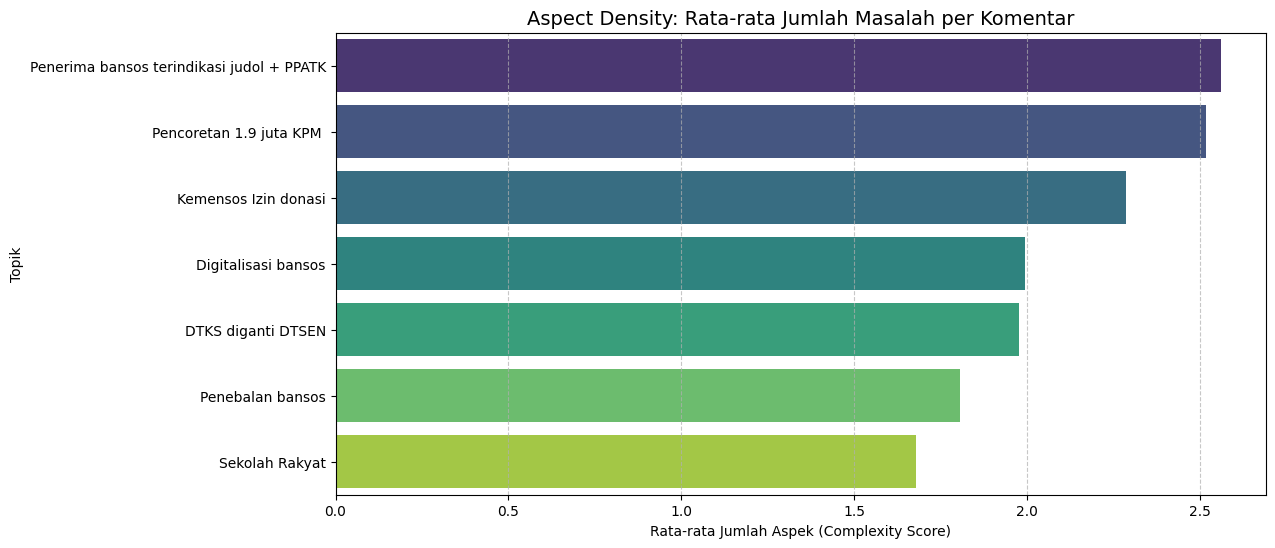

In [ ]:
# Menghitung rata-rata jumlah aspek per topik
density_analysis = df_03.groupby('Topik')['aspect_count'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=density_analysis.values, y=density_analysis.index, palette='viridis')
plt.title('Aspect Density: Rata-rata Jumlah Masalah per Komentar', fontsize=14)
plt.xlabel('Rata-rata Jumlah Aspek (Complexity Score)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

## Keyword Attribution

In [ ]:
# Mengexplode kolom keywords_found agar di breakdown per keyword
df_keywords = df_03.explode(['keywords_found', 'sub_aspect_list'])

In [ ]:
df_03

,Text,Tanggal,Topik,Sumber,length,Jam,Text_Normalized,total_words,unique_words,unique_ratio,sentiment,sub_aspect_list,keywords_found,primary_aspect,aspect_count,is_multi_issue
0,data pkh yg sllu utama datanya tdk prnh dperba...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,81,15,data program keluarga harapan yang selalu ut...,18,18,1.000000,positive,"[Keadilan & Dampak Sosial, Akurasi & Sistem, K...","[keluarga, data, harapan]",Keadilan & Dampak Sosial,3,True
1,saya cek desil saya 2 tapi gk pernah dpt bansos,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,47,15,saya cek desil saya 2 tapi tidak pernah dapat ...,11,10,0.909091,negative,"[Akurasi & Sistem, Keadilan & Dampak Sosial]","[desil, sosial]",Akurasi & Sistem,2,True
2,betul pak masa sy desil 8 gak punya ap ap masu...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,62,15,betul pak masa saya desil 8 tidak punya ap ap...,13,12,0.923077,negative,[Akurasi & Sistem],[desil],Akurasi & Sistem,1,False
3,pantesan saya ga pernah dpt bansos ga tau ny s...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,57,15,pantas saya tidak pernah dapat bantuan sosia...,13,11,0.846154,negative,"[Akurasi & Sistem, Keadilan & Dampak Sosial]","[desil, sosial]",Akurasi & Sistem,2,True
4,tdk pernah ada yg survey dan tiba2 ada d desil...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,86,15,tidak pernah ada yang survey dan tiba2 ada d ...,18,15,0.833333,negative,"[Akurasi & Sistem, Akurasi & Sistem]","[survey, desil]",Akurasi & Sistem,2,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26238,jawir gak tau adab,2025-12-13 14:22:28,Kemensos Izin donasi,Youtube,18,14,jawir tidak tahu adab,4,4,1.000000,negative,[Lainnya / Umum],[],Lainnya / Umum,1,False
26239,ora mutu blas uasuuuu,2025-12-15 07:33:57,Kemensos Izin donasi,Youtube,26,7,ora mutu blas uasuuuu,4,4,1.000000,negative,[Lainnya / Umum],[],Lainnya / Umum,1,False
26240,blunder,2025-12-13 19:48:25,Kemensos Izin donasi,Youtube,7,19,blunder,1,1,1.000000,negative,[Kinerja & Birokrasi],[blunder],Kinerja & Birokrasi,1,False
26241,stop basa basi,2025-12-12 15:47:29,Kemensos Izin donasi,Youtube,14,15,stop basa basi,3,3,1.000000,negative,[Solidaritas & Sinisme],[basa basi],Solidaritas & Sinisme,1,False


In [ ]:
# Remove baris yang tidak memiliki keywords
df_keywords = df_keywords.dropna(subset=['keywords_found'])

In [ ]:
df_keywords

,Text,Tanggal,Topik,Sumber,length,Jam,Text_Normalized,total_words,unique_words,unique_ratio,sentiment,sub_aspect_list,keywords_found,primary_aspect,aspect_count,is_multi_issue
0,data pkh yg sllu utama datanya tdk prnh dperba...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,81,15,data program keluarga harapan yang selalu ut...,18,18,1.000000,positive,Keadilan & Dampak Sosial,keluarga,Keadilan & Dampak Sosial,3,True
0,data pkh yg sllu utama datanya tdk prnh dperba...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,81,15,data program keluarga harapan yang selalu ut...,18,18,1.000000,positive,Akurasi & Sistem,data,Keadilan & Dampak Sosial,3,True
0,data pkh yg sllu utama datanya tdk prnh dperba...,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,81,15,data program keluarga harapan yang selalu ut...,18,18,1.000000,positive,Keadilan & Dampak Sosial,harapan,Keadilan & Dampak Sosial,3,True
1,saya cek desil saya 2 tapi gk pernah dpt bansos,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,47,15,saya cek desil saya 2 tapi tidak pernah dapat ...,11,10,0.909091,negative,Akurasi & Sistem,desil,Akurasi & Sistem,2,True
1,saya cek desil saya 2 tapi gk pernah dpt bansos,2025-10-09 15:53:20,DTKS diganti DTSEN,Tiktok,47,15,saya cek desil saya 2 tapi tidak pernah dapat ...,11,10,0.909091,negative,Keadilan & Dampak Sosial,sosial,Akurasi & Sistem,2,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26236,ribet mau bantu bencana alam juga ada yg mau b...,2025-12-16 21:32:57,Kemensos Izin donasi,Youtube,371,21,ribet mau bantu bencana alam juga ada yang ma...,55,47,0.854545,negative,Kinerja & Birokrasi,ribet,Integritas & Politik,6,True
26236,ribet mau bantu bencana alam juga ada yg mau b...,2025-12-16 21:32:57,Kemensos Izin donasi,Youtube,371,21,ribet mau bantu bencana alam juga ada yang ma...,55,47,0.854545,negative,Keadilan & Dampak Sosial,harapan,Integritas & Politik,6,True
26237,mentri rusak,2025-12-16 13:57:03,Kemensos Izin donasi,Youtube,12,13,mentri rusak,2,2,1.000000,negative,Integritas & Politik,menteri,Integritas & Politik,1,False
26240,blunder,2025-12-13 19:48:25,Kemensos Izin donasi,Youtube,7,19,blunder,1,1,1.000000,negative,Kinerja & Birokrasi,blunder,Kinerja & Birokrasi,1,False


In [ ]:
# Menghapus kolom tidak perlu
df_keywords = df_keywords[['keywords_found','Topik', 'sub_aspect_list', 'sentiment', 'Sumber']]

In [ ]:
df_keywords.to_csv('keywords.csv', index=False)

In [ ]:
# Meledakkan keywords_found agar bisa dihitung satu per satu
df_keywords = df_03.explode('keywords_found')

# Mencari 5 keyword teratas untuk 3 aspek paling bermasalah
top_aspects = df_03['primary_aspect'].value_counts().head(3).index

print("--- TOP TRIGGER WORDS PER ASPECT ---")
for aspect in top_aspects:
    top_kw = df_keywords[df_keywords['primary_aspect'] == aspect]['keywords_found'].value_counts().head(5)
    print(f"\nAspek: {aspect}")
    print(top_kw)

--- TOP TRIGGER WORDS PER ASPECT ---

Aspek: Lainnya / Umum
Series([], Name: count, dtype: int64)

Aspek: Keadilan & Dampak Sosial
keywords_found
rakyat      1889
sosial      1417
keluarga     707
iri          689
rt           676
Name: count, dtype: int64

Aspek: Integritas & Politik
keywords_found
menteri       1503
sosial        1095
rt            1014
pemerintah     887
uang           672
Name: count, dtype: int64


## Platform Behavior

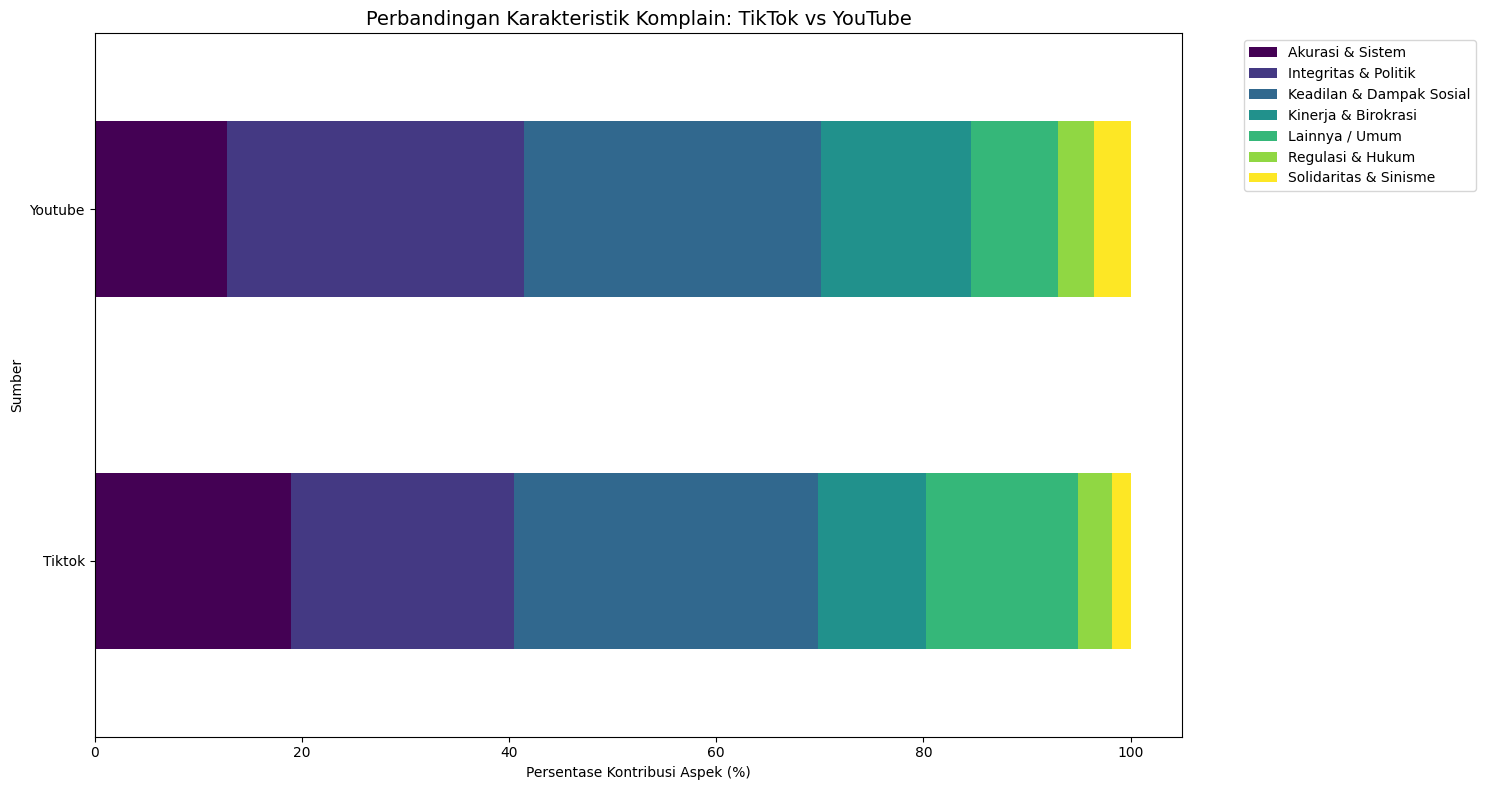

In [ ]:
# Perbandingan distribusi aspek antar platform
platform_aspect = pd.crosstab(df_exploded['Sumber'], df_exploded['sub_aspect_list'], normalize='index') * 100

platform_aspect.plot(kind='barh', stacked=True, figsize=(15, 8), colormap='viridis')
plt.title('Perbandingan Karakteristik Komplain: TikTok vs YouTube', fontsize=14)
plt.xlabel('Persentase Kontribusi Aspek (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Multi-Issue Persona Analysis

--- SEGMENTASI PERSONA NETIZEN ---
         Focused Critics (1 Issue)  Angry Generalists (>1 Issues)
Sumber                                                           
Tiktok                       55.30                          44.70
Youtube                      43.53                          56.47


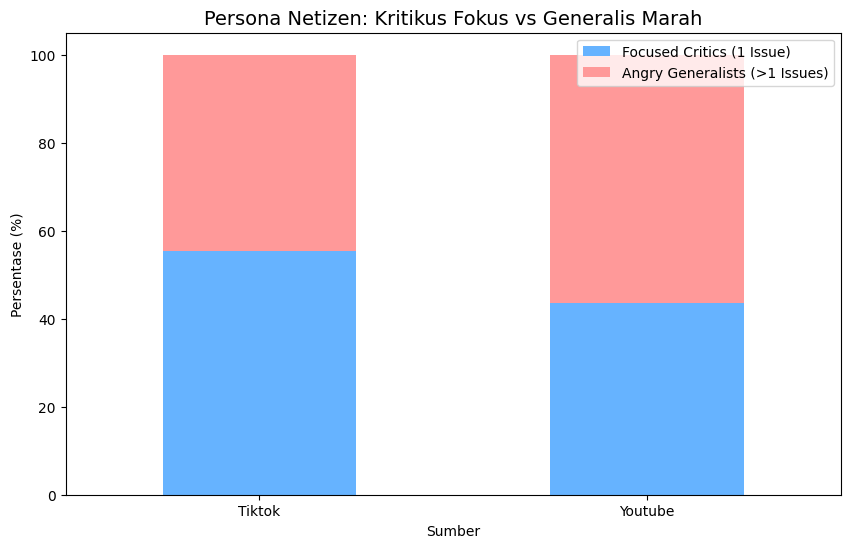

In [ ]:
# Menghitung rasio Persona
persona_stats = df_03.groupby('Sumber')['is_multi_issue'].value_counts(normalize=True).unstack() * 100
persona_stats.columns = ['Focused Critics (1 Issue)', 'Angry Generalists (>1 Issues)']

print("--- SEGMENTASI PERSONA NETIZEN ---")
print(persona_stats.round(2))

# Visualisasi Rasio
persona_stats.plot(kind='bar', stacked=True, color=['#66b3ff','#ff9999'], figsize=(10, 6))
plt.title('Persona Netizen: Kritikus Fokus vs Generalis Marah', fontsize=14)
plt.ylabel('Persentase (%)')
plt.xticks(rotation=0)
plt.show()